# SQLite + pandas: a mini relational demo

An in-memory SQLite database with two tables (`customers`, `orders`), a JOIN
query loaded into pandas, and a groupby aggregation visualised as a bar chart.

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(0)

## 1. Open an in-memory database and create the schema

In [2]:
conn = sqlite3.connect(":memory:")
cur = conn.cursor()

cur.executescript('''
    CREATE TABLE customers (
        customer_id INTEGER PRIMARY KEY,
        name TEXT NOT NULL,
        city TEXT NOT NULL
    );
    CREATE TABLE orders (
        order_id INTEGER PRIMARY KEY,
        customer_id INTEGER NOT NULL,
        amount REAL NOT NULL,
        FOREIGN KEY(customer_id) REFERENCES customers(customer_id)
    );
''')
conn.commit()

## 2. Insert ~30 rows: 6 customers and 25 orders

In [3]:
customers = [
    (1, "Awa",     "Cotonou"),
    (2, "Bako",    "Porto-Novo"),
    (3, "Chidi",   "Cotonou"),
    (4, "Daba",    "Parakou"),
    (5, "Eli",     "Porto-Novo"),
    (6, "Fatou",   "Parakou"),
]
cur.executemany("INSERT INTO customers VALUES (?,?,?)", customers)

customer_ids = np.random.randint(1, 7, size=25)
amounts = np.round(np.random.uniform(5.0, 150.0, size=25), 2)
orders = [(i + 1, int(cid), float(a)) for i, (cid, a) in enumerate(zip(customer_ids, amounts))]
cur.executemany("INSERT INTO orders VALUES (?,?,?)", orders)
conn.commit()

print("customers:", cur.execute("SELECT COUNT(*) FROM customers").fetchone()[0])
print("orders:   ", cur.execute("SELECT COUNT(*) FROM orders").fetchone()[0])

customers: 6
orders:    25


## 3. JOIN query → pandas DataFrame

Load the joined result directly with `pd.read_sql_query`.

In [4]:
query = '''
    SELECT c.customer_id, c.name, c.city, o.order_id, o.amount
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    ORDER BY c.customer_id, o.order_id;
'''
df = pd.read_sql_query(query, conn)
df.head(8)

,customer_id,name,city,order_id,amount
0,1,Awa,Cotonou,3,25.35
1,1,Awa,Cotonou,12,115.00
2,1,Awa,Cotonou,13,20.36
3,1,Awa,Cotonou,17,36.40
4,1,Awa,Cotonou,22,61.04
5,2,Bako,Porto-Novo,7,80.47
6,2,Bako,Porto-Novo,16,111.85
7,2,Bako,Porto-Novo,18,24.61


## 4. Groupby aggregation: total spend per city

In [5]:
by_city = df.groupby("city")["amount"].sum().sort_values(ascending=False)
by_city

city
Parakou       865.81
Porto-Novo    664.74
Cotonou       379.56
Name: amount, dtype: float64

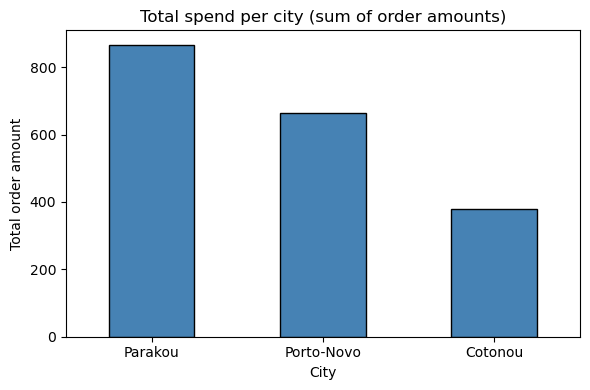

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
by_city.plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")
ax.set_xlabel("City")
ax.set_ylabel("Total order amount")
ax.set_title("Total spend per city (sum of order amounts)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
conn.close()

## Exercises

1. Add a `product` column to `orders` and rewrite the aggregation to compute
   total spend per (city, product) pair.
2. Replace the JOIN with a correlated subquery that returns, for each customer,
   their highest single order. Verify both approaches yield the same answer.
3. Build an index on `orders.customer_id` and measure the effect on query
   plans with `EXPLAIN QUERY PLAN`.